In [ ]:
import heapq
import itertools
import matplotlib.pyplot as plt
import matplotlib.animation as animation

from IPython.display import HTML, display
from graphviz import Digraph

initial_state = (
    2, 8, 3,
    1, 6, 4,
    7, 0, 5
)

goal_state = (
    1, 2, 3,
    8, 0, 4,
    7, 6, 5
)

def show_board(state):
    for i in range(0, 9, 3):
        print(*state[i:i+3])
    print()

print("Initial State:")
show_board(initial_state)

print("Goal State:")
show_board(goal_state)

Initial State:
2 8 3
1 6 4
7 0 5

Goal State:
1 2 3
8 0 4
7 6 5



In [ ]:
def get_neighbors(state):
    neighbors = []

    blank = state.index(0)
    row, col = divmod(blank, 3)

    moves = [
        (-1, 0, "UP"),
        (1, 0, "DOWN"),
        (0, -1, "LEFT"),
        (0, 1, "RIGHT")
    ]

    for dr, dc, action in moves:
        nr, nc = row + dr, col + dc

        if 0 <= nr < 3 and 0 <= nc < 3:
            new_blank = nr * 3 + nc
            board = list(state)

            board[blank], board[new_blank] = (
                board[new_blank], board[blank]
            )

            neighbors.append((tuple(board), action))

    return neighbors

In [ ]:
def misplaced_tiles(state, goal):
    return sum(
        1
        for i in range(9)
        if state[i] != 0 and state[i] != goal[i]
    )

In [ ]:
def manhattan_distance(state, goal):
    goal_positions = {
        tile: divmod(i, 3)
        for i, tile in enumerate(goal)
        if tile != 0
    }

    distance = 0

    for i, tile in enumerate(state):
        if tile == 0:
            continue

        row, col = divmod(i, 3)
        goal_row, goal_col = goal_positions[tile]

        distance += (
            abs(row - goal_row)
            + abs(col - goal_col)
        )

    return distance

In [ ]:
def astar(initial, goal, heuristic):
    counter = itertools.count()

    # (f, tie-breaker, g, state)
    frontier = [
        (heuristic(initial, goal), next(counter), 0, initial)
    ]

    best_g = {initial: 0}
    parent = {initial: (None, None)}
    expanded = set()
    edges = []

    while frontier:
        f, _, g, state = heapq.heappop(frontier)

        # Ignore outdated queue entries
        if g != best_g.get(state):
            continue

        if state in expanded:
            continue

        expanded.add(state)

        if state == goal:
            path = []
            current = goal

            while current != initial:
                previous, action = parent[current]
                path.append((action, current))
                current = previous

            path.reverse()

            return {
                "path": path,
                "expanded": expanded,
                "edges": edges,
                "cost": g
            }

        for next_state, action in get_neighbors(state):
            new_g = g + 1

            if new_g < best_g.get(next_state, float("inf")):
                best_g[next_state] = new_g
                parent[next_state] = (state, action)

                new_f = new_g + heuristic(next_state, goal)

                heapq.heappush(
                    frontier,
                    (new_f, next(counter), new_g, next_state)
                )

                edges.append((state, next_state, action))

    return None

In [ ]:
result_misplaced = astar(
    initial_state,
    goal_state,
    misplaced_tiles
)

result_manhattan = astar(
    initial_state,
    goal_state,
    manhattan_distance
)

def print_result(name, result, heuristic):
    print("=" * 45)
    print(name)

    if result is None:
        print("No solution found.")
        return

    print("Initial heuristic:", heuristic(initial_state, goal_state))
    print("Solution cost:", result["cost"])
    print("Moves:", len(result["path"]))
    print("States expanded:", len(result["expanded"]))

print_result(
    "CASE 1: MISPLACED TILES",
    result_misplaced,
    misplaced_tiles
)

print_result(
    "CASE 2: MANHATTAN DISTANCE",
    result_manhattan,
    manhattan_distance
)

CASE 1: MISPLACED TILES
Initial heuristic: 4
Solution cost: 5
Moves: 5
States expanded: 7
CASE 2: MANHATTAN DISTANCE
Initial heuristic: 5
Solution cost: 5
Moves: 5
States expanded: 6


In [ ]:
def show_solution(initial, result):
    if result is None:
        print("No solution available.")
        return

    print("Initial State:")
    show_board(initial)

    for step, (action, state) in enumerate(result["path"], start=1):
        print(f"Step {step}: Move blank {action}")
        show_board(state)

    print("Total moves:", len(result["path"]))

print("CASE 1: MISPLACED TILES")
show_solution(initial_state, result_misplaced)

print("CASE 2: MANHATTAN DISTANCE")
show_solution(initial_state, result_manhattan)

CASE 1: MISPLACED TILES
Initial State:
2 8 3
1 6 4
7 0 5

Step 1: Move blank UP
2 8 3
1 0 4
7 6 5

Step 2: Move blank UP
2 0 3
1 8 4
7 6 5

Step 3: Move blank LEFT
0 2 3
1 8 4
7 6 5

Step 4: Move blank DOWN
1 2 3
0 8 4
7 6 5

Step 5: Move blank RIGHT
1 2 3
8 0 4
7 6 5

Total moves: 5
CASE 2: MANHATTAN DISTANCE
Initial State:
2 8 3
1 6 4
7 0 5

Step 1: Move blank UP
2 8 3
1 0 4
7 6 5

Step 2: Move blank UP
2 0 3
1 8 4
7 6 5

Step 3: Move blank LEFT
0 2 3
1 8 4
7 6 5

Step 4: Move blank DOWN
1 2 3
0 8 4
7 6 5

Step 5: Move blank RIGHT
1 2 3
8 0 4
7 6 5

Total moves: 5


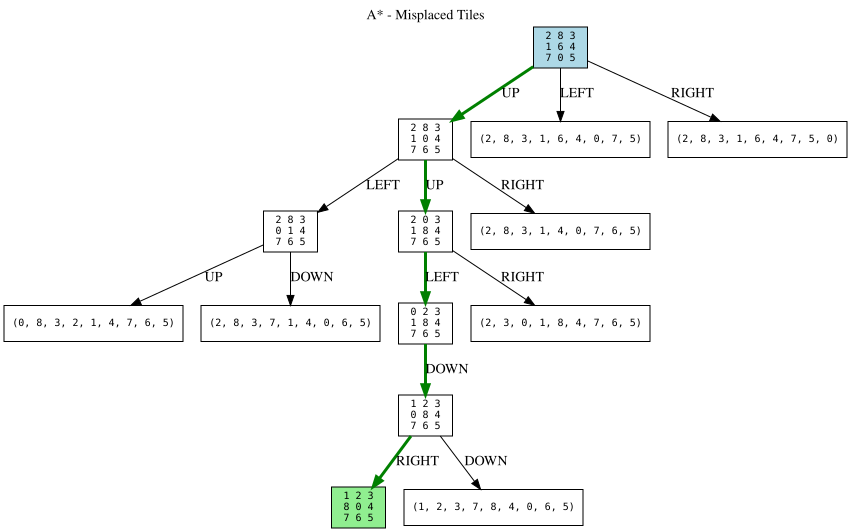

In [ ]:
def visualize_astar(initial, goal, result, title):
    if result is None:
        print("No search result to visualize.")
        return

    graph = Digraph(title)
    graph.attr(
        rankdir="TB",
        size="14,12",
        label=title,
        labelloc="t"
    )
    graph.attr("node", shape="box", fontname="monospace", fontsize="10")

    def board_label(state):
        return (
            f"{state[0]} {state[1]} {state[2]}\n"
            f"{state[3]} {state[4]} {state[5]}\n"
            f"{state[6]} {state[7]} {state[8]}"
        )

    path_states = [initial] + [
        state for _, state in result["path"]
    ]

    path_edges = {
        (path_states[i], path_states[i + 1])
        for i in range(len(path_states) - 1)
    }

    # Include all expanded states and states on the solution path
    nodes = set(result["expanded"]) | set(path_states)

    for state in nodes:
        attrs = {"label": board_label(state)}

        if state == initial:
            attrs.update(style="filled", fillcolor="lightblue")
        elif state == goal:
            attrs.update(style="filled", fillcolor="lightgreen")

        graph.node(str(state), **attrs)

    added_edges = set()

    for src, dst, action in result["edges"]:
        edge = (src, dst)

        if edge in added_edges:
            continue

        added_edges.add(edge)

        attrs = {"label": action}

        if edge in path_edges:
            attrs.update(color="green", penwidth="3")

        graph.edge(str(src), str(dst), **attrs)

    return graph

graph1 = visualize_astar(
    initial_state,
    goal_state,
    result_misplaced,
    "A* - Misplaced Tiles"
)

graph1

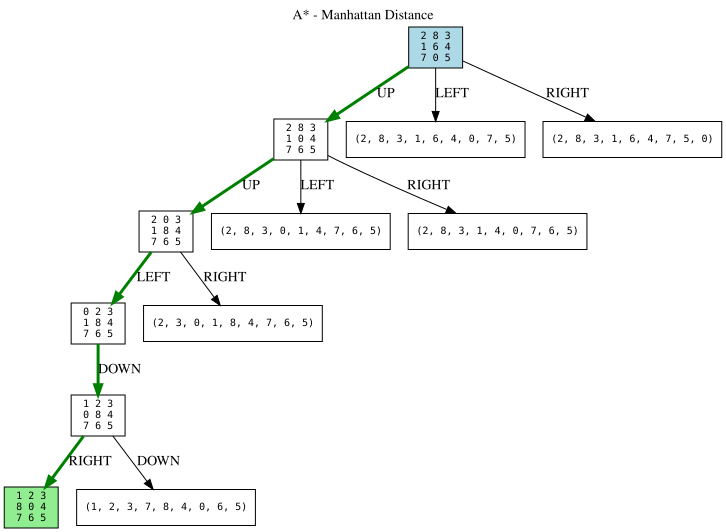

In [ ]:
graph2 = visualize_astar(
    initial_state,
    goal_state,
    result_manhattan,
    "A* - Manhattan Distance"
)

graph2